In [53]:
import pandas as pd
 
data = {
    "Outlook": [
        "Sunny", "Sunny", "Overcast", "Rain",
        "Rain", "Rain", "Overcast", "Sunny",
        "Sunny", "Rain", "Sunny", "Overcast",
        "Overcast", "Rain"
    ],
    "Temperature": [
        "Hot", "Hot", "Hot", "Mild",
        "Cool", "Cool", "Cool", "Mild",
        "Cool", "Mild", "Mild", "Mild",
        "Hot", "Mild"
    ],
    "Humidity": [
        "High", "High", "High", "High",
        "Normal", "Normal", "Normal", "High",
        "Normal", "Normal", "Normal", "High",
        "Normal", "High"
    ],
    "Wind": [
        "Weak", "Strong", "Weak", "Weak",
        "Weak", "Strong", "Strong", "Weak",
        "Weak", "Weak", "Strong", "Strong",
        "Weak", "Strong"
    ],
    "Play": [
        "No", "No", "Yes", "Yes",
        "Yes", "No", "Yes", "No",
        "Yes", "Yes", "Yes", "Yes",
        "Yes", "No"
    ]
}
 
df = pd.DataFrame(data)

Identify unique values in each feature

In [54]:
for column in df.columns:
    print(column, ":", df[column].unique())

Outlook : <ArrowStringArray>
['Sunny', 'Overcast', 'Rain']
Length: 3, dtype: str
Temperature : <ArrowStringArray>
['Hot', 'Mild', 'Cool']
Length: 3, dtype: str
Humidity : <ArrowStringArray>
['High', 'Normal']
Length: 2, dtype: str
Wind : <ArrowStringArray>
['Weak', 'Strong']
Length: 2, dtype: str
Play : <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str


Count Yes and No records

In [55]:
print(df["Play"].value_counts())

Play
Yes    9
No     5
Name: count, dtype: int64


Count total number of records

In [56]:
print("Total number of records:", len(df))

Total number of records: 14


Identify target variable

In [57]:
target_variable = "Play"

print("Target Variable:", target_variable)

Target Variable: Play


Identify input features

In [58]:
input_features = df.drop(columns=["Play"]).columns.tolist()

print("Input Features:", input_features)

Input Features: ['Outlook', 'Temperature', 'Humidity', 'Wind']


Display final dataset information

In [59]:
print("Dataset Shape:", df.shape)
print("Total Records:", df.shape[0])
print("Input Features:", input_features)
print("Target Variable:", target_variable)
print("\nTarget Count:")
print(df[target_variable].value_counts())

Dataset Shape: (14, 5)
Total Records: 14
Input Features: ['Outlook', 'Temperature', 'Humidity', 'Wind']
Target Variable: Play

Target Count:
Play
Yes    9
No     5
Name: count, dtype: int64


Calculate Parent Gini of entire dataset

In [60]:
# Count Yes and No
yes = (df["Play"] == "Yes").sum()
no = (df["Play"] == "No").sum()

# Total records
total = len(df)

# Calculate probabilities
p_yes = yes / total
p_no = no / total

# Calculate Parent Gini
parent_gini = 1 - (p_yes**2 + p_no**2)

print("Total Records:", total)
print("Yes Count:", yes)
print("No Count:", no)
print("Parent Gini:", round(parent_gini, 4))

Total Records: 14
Yes Count: 9
No Count: 5
Parent Gini: 0.4592


Gini reduction.

In [61]:
def calculate_gini(data):
    counts = data.value_counts()
    total = len(data)

    gini = 1

    for count in counts:
        probability = count / total
        gini -= probability ** 2

    return gini

Calculate Parent Gini

In [62]:
parent_gini = calculate_gini(df["Play"])

print("Parent Gini:", round(parent_gini, 4))

Parent Gini: 0.4592


Generate all possible binary splits

In [63]:
from itertools import combinations

splits = []

for feature in df.columns[:-1]:

    values = df[feature].unique()

    if len(values) == 2:
        splits.append((feature, [values[0]], [values[1]]))

    else:
        for value in values:
            left = [value]
            right = [v for v in values if v != value]

            splits.append((feature, left, right))

print("Total Binary Splits:", len(splits))

Total Binary Splits: 8


Calculate all Gini values

In [64]:
results = []

for feature, left_values, right_values in splits:

    left_data = df[df[feature].isin(left_values)]["Play"]
    right_data = df[df[feature].isin(right_values)]["Play"]

    # Child Gini
    left_gini = calculate_gini(left_data)
    right_gini = calculate_gini(right_data)

    # Weighted Child Gini
    weighted_gini = (
        (len(left_data) / len(df)) * left_gini +
        (len(right_data) / len(df)) * right_gini
    )

    # Gini Reduction
    gini_reduction = parent_gini - weighted_gini

    results.append({
        "Feature": feature,
        "Left Split": str(left_values),
        "Right Split": str(right_values),
        "Left Gini": round(left_gini, 4),
        "Right Gini": round(right_gini, 4),
        "Weighted Gini": round(weighted_gini, 4),
        "Gini Reduction": round(gini_reduction, 4)
    })

result_df = pd.DataFrame(results)

result_df

,Feature,Left Split,Right Split,Left Gini,Right Gini,Weighted Gini,Gini Reduction
0,Outlook,['Sunny'],"['Overcast', 'Rain']",0.4800,0.3457,0.3937,0.0655
1,Outlook,['Overcast'],"['Sunny', 'Rain']",0.0000,0.5000,0.3571,0.1020
2,Outlook,['Rain'],"['Sunny', 'Overcast']",0.4800,0.4444,0.4571,0.0020
3,Temperature,['Hot'],"['Mild', 'Cool']",0.5000,0.4200,0.4429,0.0163
4,Temperature,['Mild'],"['Hot', 'Cool']",0.4444,0.4688,0.4583,0.0009
5,Temperature,['Cool'],"['Hot', 'Mild']",0.3750,0.4800,0.4500,0.0092
6,Humidity,['High'],['Normal'],0.4898,0.2449,0.3673,0.0918
7,Wind,['Weak'],['Strong'],0.3750,0.5000,0.4286,0.0306


4. Final conclusion
Best split: Outlook = Overcast
- Parent Gini = 0.4592
- Left Child Gini = 0.0000
- Right Child Gini = 0.5000
- Weighted Child Gini = 0.3571
- Gini Reduction = 0.1020
Conclusion: The best binary split is Overcast vs (Sunny, Rain) because it gives the highest Gini reduction of 0.1020.

In [65]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

In [66]:
X = pd.get_dummies(df.drop("Play", axis=1))
y = df["Play"]

print("Input Features:")
display(X)

print("Target Variable:")
print(y)

Input Features:


,Outlook_Overcast,Outlook_Rain,Outlook_Sunny,Temperature_Cool,Temperature_Hot,Temperature_Mild,Humidity_High,Humidity_Normal,Wind_Strong,Wind_Weak
0,False,False,True,False,True,False,True,False,False,True
1,False,False,True,False,True,False,True,False,True,False
2,True,False,False,False,True,False,True,False,False,True
3,False,True,False,False,False,True,True,False,False,True
4,False,True,False,True,False,False,False,True,False,True
5,False,True,False,True,False,False,False,True,True,False
6,True,False,False,True,False,False,False,True,True,False
7,False,False,True,False,False,True,True,False,False,True
8,False,False,True,True,False,False,False,True,False,True
9,False,True,False,False,False,True,False,True,False,True


Target Variable:
0      No
1      No
2     Yes
3     Yes
4     Yes
5      No
6     Yes
7      No
8     Yes
9     Yes
10    Yes
11    Yes
12    Yes
13     No
Name: Play, dtype: str


In [67]:
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

model.fit(X, y)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [68]:
y_pred = model.predict(X)

result = pd.DataFrame({
    "Actual": y,
    "Predicted": y_pred
})

display(result)

,Actual,Predicted
0,No,No
1,No,No
2,Yes,Yes
3,Yes,No
4,Yes,Yes
5,No,No
6,Yes,Yes
7,No,No
8,Yes,Yes
9,Yes,Yes


In [69]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 85.71428571428571 %


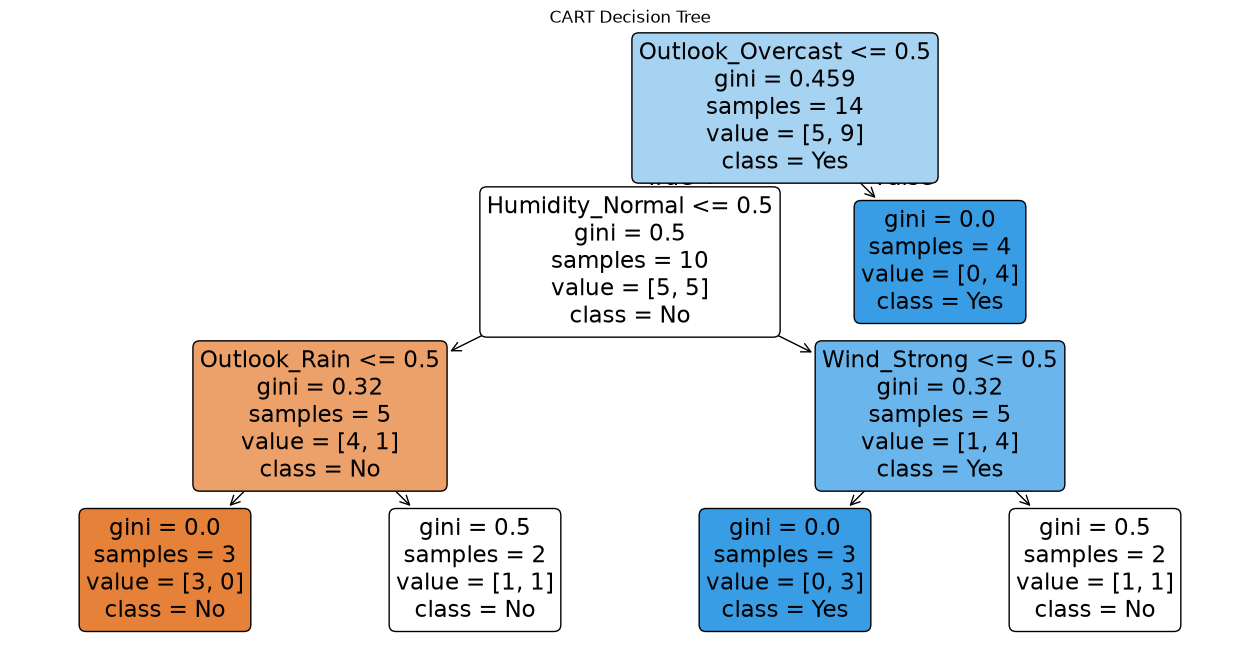

In [70]:
plt.figure(figsize=(16, 8))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True,
    rounded=True
)

plt.title("CART Decision Tree")
plt.show()

In [71]:
new_data = pd.DataFrame([{
    "Outlook": "Sunny",
    "Temperature": "Cool",
    "Humidity": "Normal",
    "Wind": "Weak"
}])

new_data = pd.get_dummies(new_data)
new_data = new_data.reindex(columns=X.columns, fill_value=0)

prediction = model.predict(new_data)

print("Play Prediction:", prediction[0])

Play Prediction: Yes


Summary:

In this activity, I implemented the CART (Classification and Regression Trees) algorithm using Python. We created a weather dataset and identified its input features and target variable. We calculated the Parent Gini impurity and evaluated all possible binary splits using Left Gini, Right Gini, Weighted Child Gini, and Gini Reduction. Finally, we implemented a Decision Tree using the Gini criterion, predicted the output, calculated accuracy, and visualized the decision tree.